In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir() or not (PROJECT_ROOT / "data" / "raw").is_dir():
    raise FileNotFoundError("Launch Jupyter from the project root or notebooks/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
MASTER_DATASET = PROJECT_ROOT / "data" / "interim" / "f1_master_dataset.csv"
MASTER_DATASET.parent.mkdir(parents=True, exist_ok=True)

## Building the master dataset

In [2]:
from pathlib import Path
import pandas as pd

data_dir = PROJECT_ROOT / "data" / "raw"

results = pd.read_csv(data_dir / "results.csv", na_values=["\\N"])
races = pd.read_csv(data_dir / "races.csv", na_values=["\\N"])
drivers = pd.read_csv(data_dir / "drivers.csv", na_values=["\\N"])
constructors = pd.read_csv(data_dir / "constructors.csv", na_values=["\\N"])
circuits = pd.read_csv(data_dir / "circuits.csv", na_values=["\\N"])
qualifying = pd.read_csv(data_dir / "qualifying.csv", na_values=["\\N"])

df = results.merge(
    races[["raceId", "year", "round", "circuitId"]], on="raceId", how="left"
)

df = df.merge(
    drivers[["driverId", "forename", "surname", "dob", "nationality"]],
    on="driverId",
    how="left",
)

df = df.merge(
    constructors[["constructorId", "name", "nationality"]].rename(
        columns={
            "name": "constructor_name",
            "nationality": "constructor_nationality",
        }
    ),
    on="constructorId",
    how="left",
)

df = df.merge(
    circuits[["circuitId", "name", "country"]].rename(
        columns={"name": "circuit_name", "country": "circuit_country"}
    ),
    on="circuitId",
    how="left",
)

df = df.merge(
    qualifying[
        ["raceId", "driverId", "constructorId", "position", "q1", "q2", "q3"]
    ].rename(columns={"position": "qualifying_position"}),
    on=["raceId", "driverId", "constructorId"],
    how="left",
)

df["driver_name"] = df["forename"] + " " + df["surname"]
df["dob"] = pd.to_datetime(df["dob"])
df["driver_age"] = df["year"] - df["dob"].dt.year
df["starting_grid"] = df["grid"]
df["season"] = df["year"]
df["race_round"] = df["round"]
df["circuit"] = df["circuitId"]

df = df.sort_values(by=["driverId", "year", "round"]).reset_index(drop=True)

df["career_starts"] = df.groupby("driverId").cumcount()
df["career_wins"] = (
    df.groupby("driverId")["positionOrder"]
    .transform(lambda x: x.eq(1).shift(fill_value=False).cumsum())
)
df["career_podiums"] = (
    df.groupby("driverId")["positionOrder"]
    .transform(lambda x: x.le(3).shift(fill_value=False).cumsum())
)
df["career_points"] = (
    df.groupby("driverId")["points"]
    .transform(lambda x: x.shift(fill_value=0).cumsum())
)
df["avg_finish_before_race"] = (
    df.groupby("driverId")["positionOrder"]
    .transform(lambda x: x.shift().expanding().mean())
)
df["recent_form"] = (
    df.groupby("driverId")["positionOrder"]
    .transform(lambda x: x.shift().rolling(5, min_periods=1).mean())
)

df["constructor_starts"] = df.groupby("constructorId").cumcount()
df["constructor_wins"] = (
    df.groupby("constructorId")["positionOrder"]
    .transform(lambda x: x.eq(1).shift(fill_value=False).cumsum())
)
df["constructor_recent_form"] = (
    df.groupby("constructorId")["positionOrder"]
    .transform(lambda x: x.shift().rolling(5, min_periods=1).mean())
)

df.to_csv(MASTER_DATASET, index=False)
print(f"Master dataset created successfully with shape: {df.shape}")
df = pd.read_csv(MASTER_DATASET)
pd.set_option("display.max_columns", None)


Master dataset created successfully with shape: (26759, 48)


## Basic EDA

In [3]:
df.sample(10)

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,year,round,circuitId,forename,surname,dob,nationality,constructor_name,constructor_nationality,circuit_name,circuit_country,qualifying_position,q1,q2,q3,driver_name,driver_age,starting_grid,season,race_round,circuit,career_starts,career_wins,career_podiums,career_points,avg_finish_before_race,recent_form,constructor_starts,constructor_wins,constructor_recent_form
4430,1222,75,23,7,17.0,4,4.0,4,4,5.0,66,+46.719,5283549.0,63.0,6.0,1:16.469,217.829,1,2005,5,4,Ralf,Schumacher,1975-06-30,German,Toyota,Japanese,Circuit de Barcelona-Catalunya,Spain,4.0,1:14.870,1:17.047,NaN,Ralf Schumacher,30,4,2005,5,4,131,6,24,268.0,9.396947,7.0,128,0,7.4
26192,25628,1085,847,131,63.0,6,3.0,3,3,15.0,53,+16.495,5418607.0,51.0,3.0,1:37.548,215.598,1,2022,12,34,George,Russell,1998-02-15,British,Mercedes,German,Circuit Paul Ricard,France,6.0,1:33.109,1:32.633,1:32.131,George Russell,24,6,2022,12,34,71,0,4,142.0,13.464789,6.8,595,126,6.8
26552,25416,1074,854,210,47.0,12,11.0,11,11,0.0,57,+32.574,5886158.0,37.0,11.0,1:36.956,200.948,1,2022,1,3,Mick,Schumacher,1999-03-22,German,Haas F1 Team,American,Bahrain International Circuit,Bahrain,12.0,1:32.380,1:31.998,NaN,Mick Schumacher,23,12,2022,1,3,22,0,0,0.0,16.909091,17.4,356,0,17.4
25447,24051,1002,840,3,18.0,10,9.0,9,9,2.0,52,NaN,NaN,52.0,9.0,1:24.056,248.106,11,2018,14,14,Lance,Stroll,1998-10-29,Canadian,Williams,British,Autodromo Nazionale di Monza,Italy,10.0,1:21.838,1:21.494,1:21.627,Lance Stroll,20,10,2018,14,14,33,0,1,44.0,13.212121,14.6,1413,114,14.6
11665,8113,362,137,32,11.0,20,8.0,8,8,0.0,78,NaN,NaN,NaN,NaN,NaN,NaN,12,1989,7,34,Nelson,Piquet,1952-08-17,Brazilian,Team Lotus,British,Circuit Paul Ricard,France,NaN,NaN,NaN,NaN,Nelson Piquet,37,20,1989,7,34,165,20,53,406.0,10.224242,13.0,271,6,13.0
4177,1244,76,22,6,2.0,10,8.0,8,8,1.0,78,+37.570,6353126.0,51.0,6.0,1:16.916,156.326,1,2005,6,6,Rubens,Barrichello,1972-05-23,Brazilian,Ferrari,Italian,Circuit de Monaco,Monaco,10.0,1:16.142,1:18.841,NaN,Rubens Barrichello,33,10,2005,6,6,204,9,58,459.0,10.029412,9.8,602,55,9.8
25929,25908,1101,844,6,16.0,1,3.0,3,3,15.0,51,+21.217,5583653.0,49.0,4.0,1:44.561,206.681,1,2023,4,73,Charles,Leclerc,1997-10-16,Monegasque,Ferrari,Italian,Baku City Circuit,Azerbaijan,1.0,1:41.269,1:41.037,1:40.203,Charles Leclerc,26,1,2023,4,73,106,5,24,857.0,8.320755,10.4,2395,246,10.4
25301,24082,1003,839,10,31.0,9,NaN,R,20,0.0,0,NaN,NaN,NaN,0.0,NaN,NaN,4,2018,15,15,Esteban,Ocon,1996-09-17,French,Force India,Indian,Marina Bay Street Circuit,Singapore,9.0,1:38.912,1:38.534,1:38.365,Esteban Ocon,22,9,2018,15,15,43,0,0,132.0,10.930233,8.0,417,0,8.0
24457,22836,941,826,9,26.0,11,5.0,5,5,10.0,53,+47.566,5878590.0,NaN,0.0,NaN,NaN,1,2015,15,71,Daniil,Kvyat,1994-04-26,Russian,Red Bull,Austrian,Sochi Autodrom,Russia,11.0,1:39.580,1:39.214,NaN,Daniil Kvyat,21,11,2015,15,71,33,0,1,74.0,11.757576,7.0,555,59,7.0
25493,24993,1053,840,117,18.0,10,8.0,8,8,4.0,63,+56.909,7411507.0,59.0,8.0,1:18.782,224.320,1,2021,2,21,Lance,Stroll,1998-10-29,Canadian,Aston Martin,British,Autodromo Enzo e Dino Ferrari,Italy,10.0,1:15.522,1:15.138,NaN,Lance Stroll,23,10,2021,2,21,79,0,3,143.0,12.569620,10.2,102,0,11.4


In [4]:
df.shape


(26759, 48)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 48 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   resultId                 26759 non-null  int64  
 1   raceId                   26759 non-null  int64  
 2   driverId                 26759 non-null  int64  
 3   constructorId            26759 non-null  int64  
 4   number                   26753 non-null  float64
 5   grid                     26759 non-null  int64  
 6   position                 15806 non-null  float64
 7   positionText             26759 non-null  object 
 8   positionOrder            26759 non-null  int64  
 9   points                   26759 non-null  float64
 10  laps                     26759 non-null  int64  
 11  time                     7680 non-null   object 
 12  milliseconds             7680 non-null   float64
 13  fastestLap               8252 non-null   float64
 14  rank                  

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isna().sum()

resultId                       0
raceId                         0
driverId                       0
constructorId                  0
number                         6
grid                           0
position                   10953
positionText                   0
positionOrder                  0
points                         0
laps                           0
time                       19079
milliseconds               19079
fastestLap                 18507
rank                       18249
fastestLapTime             18507
fastestLapSpeed            18507
statusId                       0
year                           0
round                          0
circuitId                      0
forename                       0
surname                        0
dob                            0
nationality                    0
constructor_name               0
constructor_nationality        0
circuit_name                   0
circuit_country                0
qualifying_position        16275
q1        

The six source tables end in 2024. Filtering to 2006 onward yields the 7,914 records used in this experiment.

In [8]:
df[df["season"]>=2006].shape

(7914, 48)

## Data cleaning

In [9]:
# filter for the modern era
df_modern = df[df["season"] >= 2006].copy()

# columns to drop
leaky_cols = [
    "position", "positionText", "points", "laps", "time", 
    "milliseconds", "fastestLap", "rank", "fastestLapTime", 
    "fastestLapSpeed", "statusId", "resultId"
]

redundant_text_cols = [
    "q1", "q2", "q3", "driver_name", "constructor_name", 
    "circuit_name", "forename", "surname", "dob"
]

# drop all leaky and useless text columns
df_clean = df_modern.drop(columns=leaky_cols + redundant_text_cols)

# fill missing qualifying positions with the starting grid
df_clean["qualifying_position"] = df_clean["qualifying_position"].fillna(df_clean["starting_grid"])

# patch rookie stats (missing prior history) with a baseline finish of 20 (back of grid)
rookie_cols = ["avg_finish_before_race", "recent_form", "constructor_recent_form"]
df_clean[rookie_cols] = df_clean[rookie_cols].fillna(20.0)

# inspect remaining missing values
print(df_clean.isna().sum())
print(f"Clean dataset shape: {df_clean.shape}")

raceId                     0
driverId                   0
constructorId              0
number                     0
grid                       0
positionOrder              0
year                       0
round                      0
circuitId                  0
nationality                0
constructor_nationality    0
circuit_country            0
qualifying_position        0
driver_age                 0
starting_grid              0
season                     0
race_round                 0
circuit                    0
career_starts              0
career_wins                0
career_podiums             0
career_points              0
avg_finish_before_race     0
recent_form                0
constructor_starts         0
constructor_wins           0
constructor_recent_form    0
dtype: int64
Clean dataset shape: (7914, 27)


In [10]:
# drop redundant duplicate columns
df_clean = df_clean.drop(columns=["grid", "year", "round", "circuit", "number"], errors="ignore")

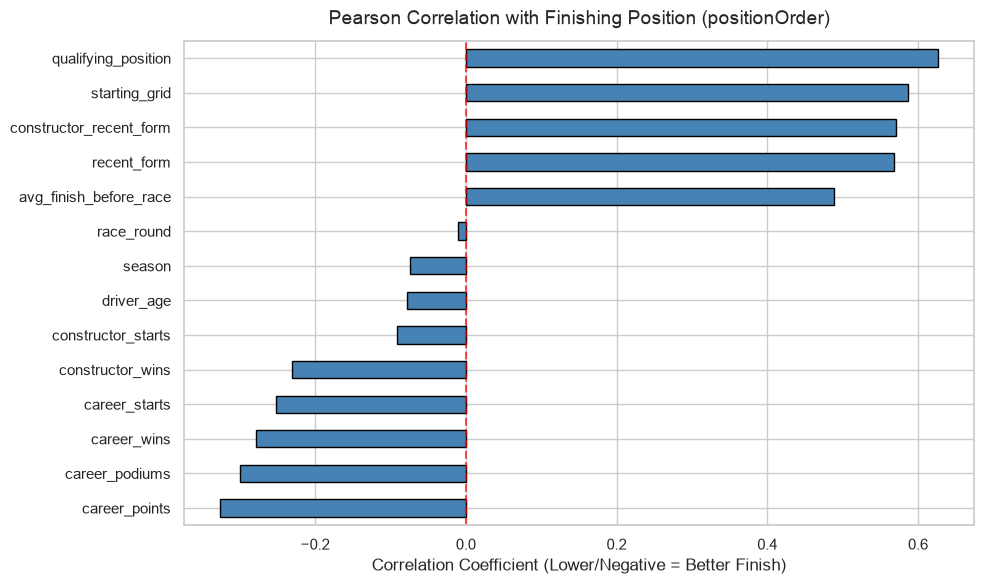

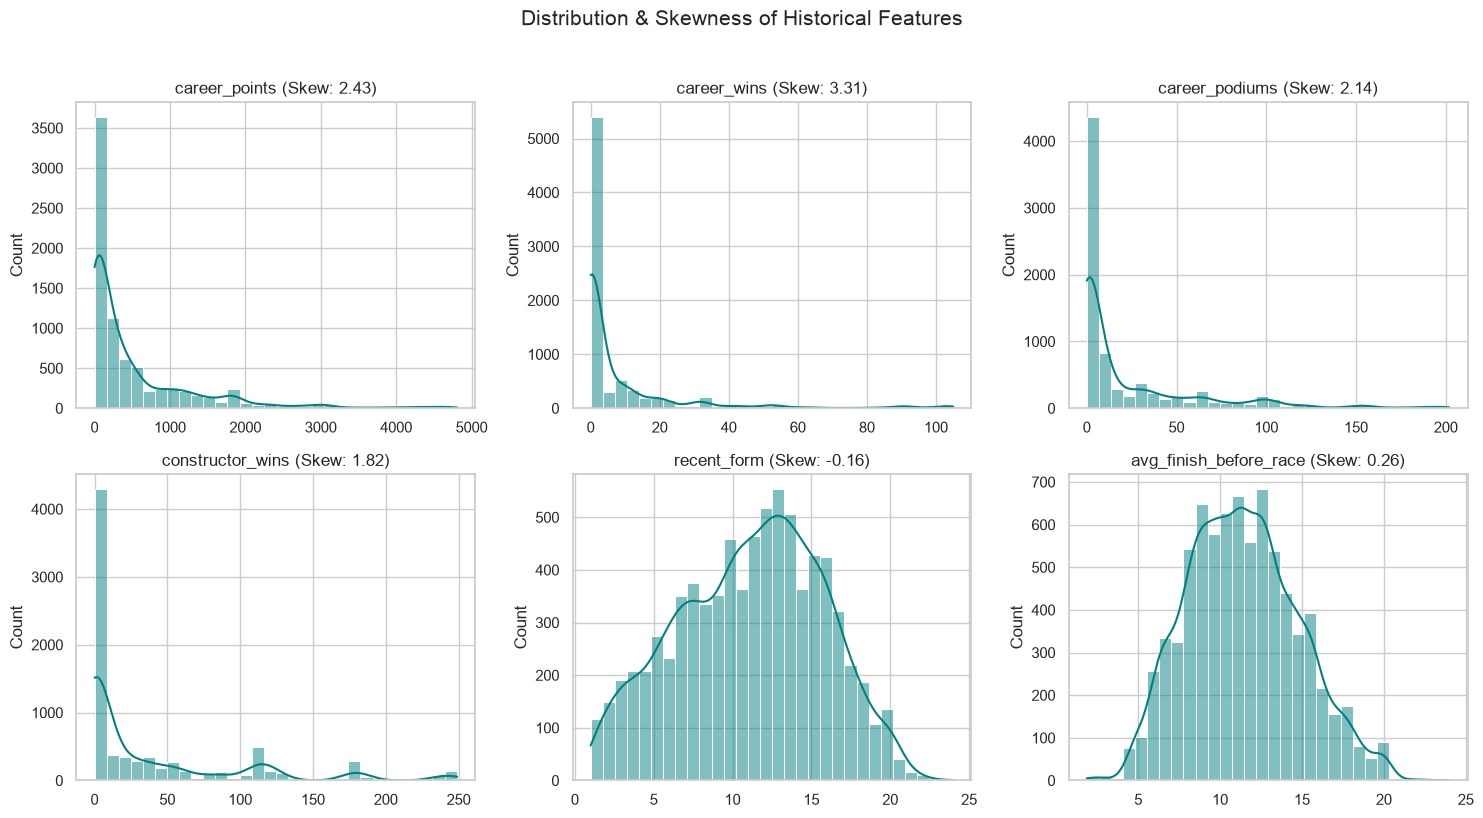

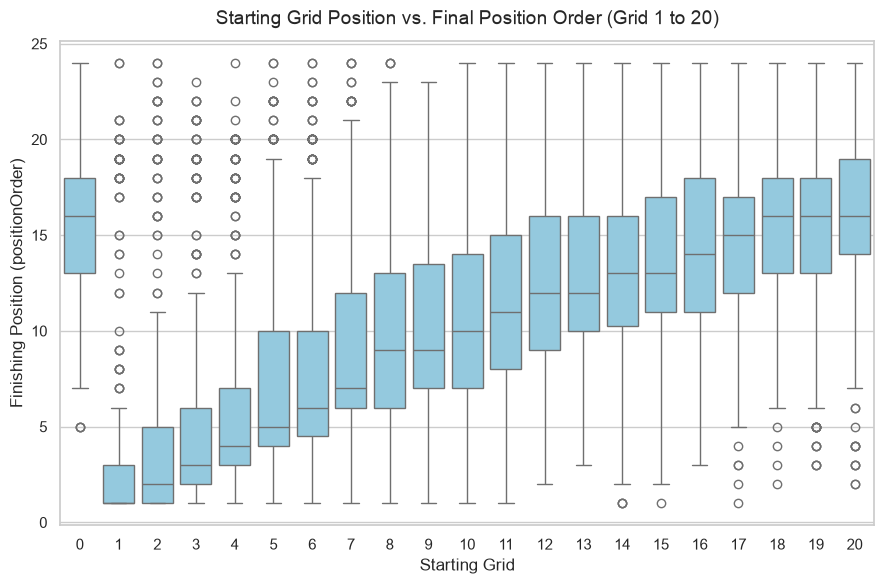

In [11]:
from src.plots import plot_data, plot_ranking_quality

plot_data(df_clean, RESULTS_DIR, show=True)

## Grouping rare categories

In [12]:
def group_rare_categories(df, columns, top_n=10):
    """
    Keeps the top_n most frequent categories in a column and 
    renames all remaining rare categories to 'Other'.
    """
    df_grouped = df.copy()
    
    for col in columns:
        top_categories = df_grouped[col].value_counts().nlargest(top_n).index
        
        df_grouped[col] = df_grouped[col].where(df_grouped[col].isin(top_categories), 'Other')
        
    return df_grouped

categorical_features = ['nationality', 'constructor_nationality', 'circuit_country']

df_clean = group_rare_categories(df_clean, categorical_features, top_n=10)

for col in categorical_features:
    print(df_clean[col].value_counts())
    print("-" * 30)

nationality
Other         1865
German        1237
British       1047
French         656
Spanish        644
Finnish        624
Brazilian      461
Australian     451
Mexican        342
Italian        318
Dutch          269
Name: count, dtype: int64
------------------------------
constructor_nationality
British      2097
Italian      1500
German        750
Austrian      750
Swiss         610
French        596
Indian        424
American      380
Japanese      324
Other         295
Malaysian     188
Name: count, dtype: int64
------------------------------
circuit_country
Other        3787
Italy         524
Spain         516
UK            422
Hungary       402
Bahrain       400
Monaco        382
Belgium       380
Brazil        378
Japan         362
Australia     361
Name: count, dtype: int64
------------------------------


In [13]:
df_clean['starting_grid'] = df_clean['starting_grid'].replace(0, 21)

# chronological train/test split
train_df = df_clean[df_clean['season'] <= 2023]
test_df = df_clean[df_clean['season'] == 2024]

X_train = train_df.drop(columns=['positionOrder', 'raceId', 'driverId', 'constructorId', 'circuitId'])
y_train = train_df['positionOrder']

X_test = test_df.drop(columns=['positionOrder', 'raceId', 'driverId', 'constructorId', 'circuitId'])
y_test = test_df['positionOrder']

## Preprocessing

In [14]:
categorical_features = ['nationality', 'constructor_nationality', 'circuit_country']

skewed_features = [
    'career_wins', 'career_podiums', 'career_points', 'constructor_wins'
]

normal_numerical_features = [
    'starting_grid', 'qualifying_position', 'driver_age', 'career_starts', 
    'avg_finish_before_race', 'recent_form', 'constructor_starts', 
    'constructor_recent_form'
]

In [15]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from category_encoders import TargetEncoder

In [16]:
log_scale_transformer = Pipeline(steps=[
    ('log1p', FunctionTransformer(np.log1p, validate=False)),
    ('scaler', StandardScaler())
])

# 4. Build the Master Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        # Apply log + scaling to skewed numericals
        ('skewed', log_scale_transformer, skewed_features),
        # Apply just scaling to normal numericals
        ('normal', StandardScaler(), normal_numerical_features),
        # Apply Target Encoding to categoricals
        ('cat', TargetEncoder(min_samples_leaf=5, smoothing=10), categorical_features)
    ],
    remainder='drop' # Drops any columns not explicitly listed above (like IDs)
)

## Evaluation and training helpers

In [17]:
import warnings
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, ndcg_score
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", message="X does not have valid feature names")

MAX_POS = 25          
predictions = {}      
fitted = {}          


def evaluate_f1_predictions(model_name, raw_scores, test_df_ref, higher_score_is_better=True):
    """
    Race-by-race evaluation of any regression or Learning-to-Rank model on the test set.
    - Regression models (predict positionOrder):  higher_score_is_better=False
    - LTR models (predict a relevance score):     higher_score_is_better=True
    raw_scores must be in the same row order as test_df_ref.
    """
    df_eval = test_df_ref[["raceId", "driverId", "positionOrder"]].copy()
    df_eval["score"] = raw_scores if higher_score_is_better else -np.asarray(raw_scores)
    df_eval["true_rel"] = np.clip(MAX_POS - df_eval["positionOrder"], 0, None)

    ndcg_3, ndcg_10, ndcg_all, spearman, winner_hits, podium_overlap, top5_overlap = [], [], [], [], [], [], []
    all_true_pos, all_pred_pos = [], []

    for _, group in df_eval.groupby("raceId", sort=False):
        group = group.sort_values("score", ascending=False).reset_index(drop=True)
        group["pred_position"] = np.arange(1, len(group) + 1)

        true_rel = group["true_rel"].to_numpy().reshape(1, -1)
        scores = group["score"].to_numpy().reshape(1, -1)
        all_true_pos.extend(group["positionOrder"])
        all_pred_pos.extend(group["pred_position"])

        ndcg_3.append(ndcg_score(true_rel, scores, k=3))
        ndcg_10.append(ndcg_score(true_rel, scores, k=10))
        ndcg_all.append(ndcg_score(true_rel, scores))
        spearman.append(spearmanr(group["positionOrder"], group["pred_position"])[0])
        winner_hits.append(int(group.loc[0, "positionOrder"] == 1))
        true_podium = set(group.loc[group["positionOrder"] <= 3, "driverId"])
        pred_podium = set(group.loc[group["pred_position"] <= 3, "driverId"])
        podium_overlap.append(len(true_podium & pred_podium) / 3)
        true_top5 = set(group.loc[group["positionOrder"] <= 5, "driverId"])
        pred_top5 = set(group.loc[group["pred_position"] <= 5, "driverId"])
        top5_overlap.append(len(true_top5 & pred_top5) / 5)

    return {
        "Model": model_name,
        "NDCG@3": np.mean(ndcg_3),
        "NDCG@10": np.mean(ndcg_10),
        "NDCG@All": np.mean(ndcg_all),
        "Spearman_Rho": np.mean(spearman),
        "Winner_Acc (%)": np.mean(winner_hits) * 100,
        "Podium_Hit (%)": np.mean(podium_overlap) * 100,
        "Top5_Hit (%)": np.mean(top5_overlap) * 100,
        "Rank_MAE": mean_absolute_error(all_true_pos, all_pred_pos),
        "Rank_RMSE": root_mean_squared_error(all_true_pos, all_pred_pos),
    }


def train_regressors(models):
    """Fit each model inside the shared preprocessing pipeline, store its test predictions, return MAE/RMSE."""
    rows = []
    for name, model in models.items():
        pipe = Pipeline([("preprocessor", clone(preprocessor)), ("model", model)]).fit(X_train, y_train)
        pred = pipe.predict(X_test)
        fitted[name] = pipe
        predictions[name] = (pred, test_df, False)
        rows.append({"Model": name,
                     "MAE": mean_absolute_error(y_test, pred),
                     "RMSE": np.sqrt(mean_squared_error(y_test, pred))})
    return pd.DataFrame(rows).round(3)

## Linear Regression and Random Forest.

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

baseline_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42, n_jobs=-1),
}
train_regressors(baseline_models)

,Model,MAE,RMSE
0,Linear Regression,2.936,3.793
1,Random Forest,3.426,4.394


## Additional regression models

In [19]:
from sklearn.linear_model import ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor

extra_models = {
    "Elastic Net": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=10),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42),
}
train_regressors(extra_models)

,Model,MAE,RMSE
0,Elastic Net,2.966,3.811
1,KNN,3.304,4.265
2,Gradient Boosting,3.388,4.460


## Tuning Elastic Net

In [20]:
from sklearn.model_selection import GridSearchCV, GroupKFold

enet_pipe = Pipeline([("preprocessor", clone(preprocessor)),
                      ("model", ElasticNet(max_iter=10000, random_state=42))])

param_grid = {
    "model__alpha": [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
}

enet_grid = GridSearchCV(enet_pipe, param_grid, scoring="neg_mean_absolute_error",
                         cv=GroupKFold(n_splits=5), n_jobs=-1)
enet_grid.fit(X_train, y_train, groups=train_df["raceId"].to_numpy())

pred_enet_tuned = enet_grid.predict(X_test)
predictions["Elastic Net (tuned)"] = (pred_enet_tuned, test_df, False)

print("Best params :", enet_grid.best_params_)
print(f"CV MAE      : {-enet_grid.best_score_:.3f}")
print(f"Test MAE    : {mean_absolute_error(y_test, pred_enet_tuned):.3f}")
print(f"Test RMSE   : {np.sqrt(mean_squared_error(y_test, pred_enet_tuned)):.3f}")

Best params : {'model__alpha': 0.001, 'model__l1_ratio': 0.1}
CV MAE      : 3.607
Test MAE    : 2.937
Test RMSE   : 3.794


## Training learning-to-rank models

In [21]:
# ranking libraries need all rows of a race to be contiguous -> sort (copies; train_df / test_df stay untouched)
sort_cols = ["season", "race_round", "raceId"]
train_ltr = train_df.sort_values(sort_cols).reset_index(drop=True)
test_ltr = test_df.sort_values(sort_cols).reset_index(drop=True)

ltr_prep = clone(preprocessor)
X_tr_ltr = np.asarray(ltr_prep.fit_transform(train_ltr[X_train.columns], train_ltr["positionOrder"]))
X_te_ltr = np.asarray(ltr_prep.transform(test_ltr[X_train.columns]))

y_tr_rel = np.clip(MAX_POS - train_ltr["positionOrder"].to_numpy(), 0, None).astype(int)
qid_tr = train_ltr["raceId"].to_numpy()


def group_sizes(qid):
    """Number of drivers per race, in order of appearance (data must be contiguous by race)."""
    return pd.Series(qid).groupby(qid, sort=False).size().to_numpy()


group_tr = group_sizes(qid_tr)
print(f"Train: {X_tr_ltr.shape[0]} rows / {len(group_tr)} races | Test: {X_te_ltr.shape[0]} rows / {test_ltr['raceId'].nunique()} races")

Train: 7435 rows / 351 races | Test: 479 rows / 24 races


## Basic rankers

In [22]:
import xgboost as xgb
import lightgbm as lgb

shared = dict(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42)

ltr_models = {
    "XGBoost LambdaMART": (xgb.XGBRanker, dict(shared, objective="rank:ndcg", ndcg_exp_gain=False)),
    "LightGBM LambdaMART": (lgb.LGBMRanker, dict(shared, objective="lambdarank", num_leaves=15, min_child_samples=30,
                                                 label_gain=[float(i ** 1.5) for i in range(MAX_POS + 1)],
                                                 n_jobs=-1, verbose=-1)),
}

basic_ltr = []
for name, (Ranker, params) in ltr_models.items():
    ranker = Ranker(**params).fit(X_tr_ltr, y_tr_rel, group=group_tr)
    scores = ranker.predict(X_te_ltr)
    predictions[name] = (scores, test_ltr, True)
    basic_ltr.append(evaluate_f1_predictions(name, scores, test_ltr, True))

basic_ltr = pd.DataFrame(basic_ltr).round(4)
best_ltr_name = basic_ltr.sort_values("NDCG@10", ascending=False).iloc[0]["Model"]
print("Best basic ranker:", best_ltr_name)
basic_ltr

Best basic ranker: LightGBM LambdaMART


,Model,NDCG@3,NDCG@10,NDCG@All,Spearman_Rho,Winner_Acc (%),Podium_Hit (%),Top5_Hit (%),Rank_MAE,Rank_RMSE
0,XGBoost LambdaMART,0.9015,0.9256,0.9641,0.7306,33.3333,61.1111,75.8333,2.9937,4.2051
1,LightGBM LambdaMART,0.9106,0.9293,0.9658,0.7131,37.5000,65.2778,73.3333,3.1232,4.3390


## Tune the selected ranker

In [23]:
from sklearn.model_selection import ParameterGrid

Ranker, base_params = ltr_models[best_ltr_name]
param_grid = {"n_estimators": [100, 300, 500], "learning_rate": [0.03, 0.1], "max_depth": [3, 5]}


def mean_ndcg(y_rel, scores, sizes, k=10):
    """Mean per-race NDCG@k."""
    out, start = [], 0
    for g in sizes:
        out.append(ndcg_score([y_rel[start:start + g]], [scores[start:start + g]], k=k))
        start += g
    return np.mean(out)


cv = GroupKFold(n_splits=4)
cv_results = []
for params in ParameterGrid(param_grid):
    fold_scores = []
    for tr, va in cv.split(X_tr_ltr, groups=qid_tr):          # indices stay in order -> races stay contiguous
        model = Ranker(**{**base_params, **params}).fit(X_tr_ltr[tr], y_tr_rel[tr], group=group_sizes(qid_tr[tr]))
        fold_scores.append(mean_ndcg(y_tr_rel[va], model.predict(X_tr_ltr[va]), group_sizes(qid_tr[va])))
    cv_results.append({**params, "cv_ndcg@10": np.mean(fold_scores)})

cv_results = pd.DataFrame(cv_results).sort_values("cv_ndcg@10", ascending=False)
best_params = cv_results.iloc[0].drop("cv_ndcg@10").to_dict()
best_params = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in best_params.items()}
print("Best params:", best_params)

tuned_ranker = Ranker(**{**base_params, **best_params}).fit(X_tr_ltr, y_tr_rel, group=group_tr)
tuned_name = f"{best_ltr_name} (tuned)"
predictions[tuned_name] = (tuned_ranker.predict(X_te_ltr), test_ltr, True)

cv_results.head()

Best params: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100}


,learning_rate,max_depth,n_estimators,cv_ndcg@10
0,0.03,3,100,0.892152
6,0.10,3,100,0.891902
3,0.03,5,100,0.891348
2,0.03,3,500,0.891216
1,0.03,3,300,0.891048


## Comparing models on 2024

In [24]:
comparison = pd.DataFrame([
    evaluate_f1_predictions(name, scores, ref, higher)
    for name, (scores, ref, higher) in predictions.items()
]).sort_values("NDCG@10", ascending=False).reset_index(drop=True)

comparison.to_csv(RESULTS_DIR / "metrics.csv", index=False)
comparison.round(4)

,Model,NDCG@3,NDCG@10,NDCG@All,Spearman_Rho,Winner_Acc (%),Podium_Hit (%),Top5_Hit (%),Rank_MAE,Rank_RMSE
0,LightGBM LambdaMART (tuned),0.9125,0.9342,0.9699,0.7468,45.8333,65.2778,80.8333,2.8852,4.0755
1,Elastic Net,0.9165,0.9334,0.9690,0.7503,45.8333,63.8889,80.0000,2.8685,4.0457
2,Linear Regression,0.9135,0.9314,0.9685,0.7476,41.6667,62.5000,80.8333,2.8935,4.0678
3,Elastic Net (tuned),0.9135,0.9314,0.9685,0.7474,41.6667,62.5000,80.8333,2.8977,4.0693
4,LightGBM LambdaMART,0.9106,0.9293,0.9658,0.7131,37.5000,65.2778,73.3333,3.1232,4.3390
5,XGBoost LambdaMART,0.9015,0.9256,0.9641,0.7306,33.3333,61.1111,75.8333,2.9937,4.2051
6,KNN,0.8837,0.9153,0.9602,0.6704,37.5000,45.8333,64.1667,3.4113,4.6470
7,Random Forest,0.9104,0.9045,0.9598,0.6340,33.3333,58.3333,68.3333,3.5157,4.9088
8,Gradient Boosting,0.8952,0.9024,0.9591,0.6168,37.5000,52.7778,71.6667,3.5115,5.0256


## Inspecting the highest-scoring model

In [25]:
best_name = comparison.loc[0, "Model"]
scores, ref, higher = predictions[best_name]

eval_df = ref[["raceId", "race_round", "starting_grid", "qualifying_position", "positionOrder"]].copy()
eval_df["score"] = scores if higher else -np.asarray(scores)
eval_df["predicted_position"] = eval_df.groupby("raceId")["score"].rank(ascending=False, method="first").astype(int)

print(f"Best model: {best_name}\n")
first_race = eval_df[eval_df["race_round"] == eval_df["race_round"].min()]
first_race[["starting_grid", "qualifying_position", "positionOrder", "predicted_position"]].sort_values("positionOrder")

Best model: LightGBM LambdaMART (tuned)



,starting_grid,qualifying_position,positionOrder,predicted_position
7,1,1.0,1,1
3,5,5.0,2,5
8,4,4.0,3,4
12,2,2.0,4,2
14,3,3.0,5,3
13,7,7.0,6,7
0,9,9.0,7,8
18,8,8.0,8,9
1,6,6.0,9,6
10,12,12.0,10,10


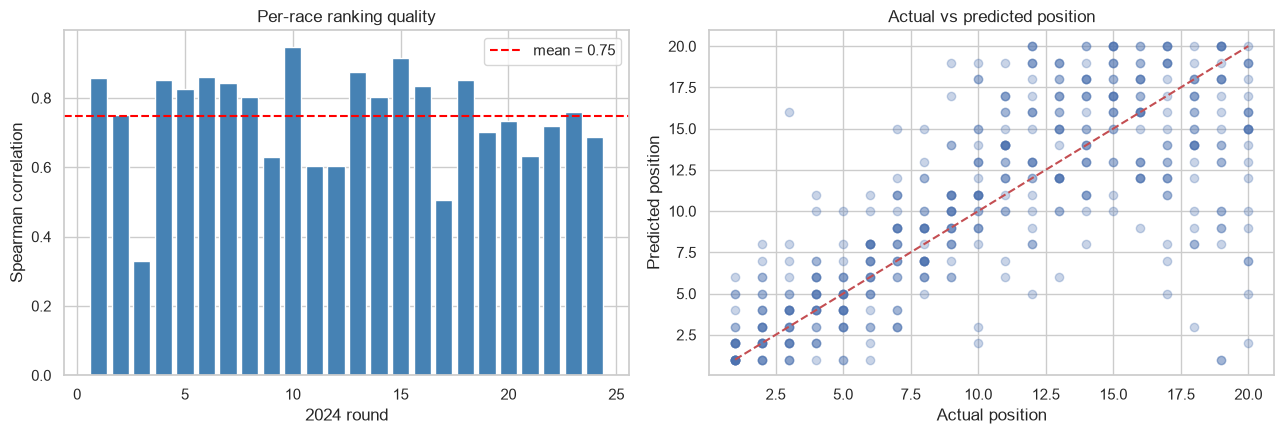

In [26]:
plot_ranking_quality(eval_df, RESULTS_DIR, show=True)